# Coffee Shop Sales Analysis
# Business Objective

Analyze coffee shop sales to identify sales trends, top-performing products, and opportunities for improvement.

## 1. Load and Preview the Dataset

Load the coffee shop sales dataset into a pandas DataFrame and preview the first five rows to understand its structure and contents.

In [20]:
import pandas as pd 
from pathlib import Path 

project_dir = Path.home() / "Documents" / "Project" 
file_path = project_dir / "Coffee Shop Sales.xlsx"
data_dir = project_dir / "data" / "raw"

df = pd.read_excel(file_path)

df.head()


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


## 2. Inspect Dataset Structure

Inspect the dataset's dimensions, column names, data types, and non-null counts to understand its structure and identify potential data quality issues before analysis.

In [21]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print(df.columns.tolist())

# Display columns names, data types, and non-null counts
df.info()

Dataset shape: (149116, 11)
['transaction_id', 'transaction_date', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  object        
 9   product_type      149116 non-null  object        
 10  produc

#### Initial Data Inspection

The dataset contains 149,116 rows and 11 columns, with approximately 12.5 MB of memory usage. It includes transaction information such as dates, times, quantities, unit prices, store locations, and product categories.

All 149,116 records have non-null values across all 11 columns, indicating that no missing values were detected during the initial inspection. The transaction date column is already in datetime format, while the transaction time column is stored as an object and requires preparation for time-based analysis.

Overall, the dataset contains the key information needed to analyze revenue patterns across products, store locations, and time periods.

### 2.1 Check Missing Values, Duplicates, and Sample Records

Check for missing values and duplicate rows to assess data completeness and consistency. Preview the first and last five rows to review the dataset's contents and confirm the range of transaction records.

In [22]:
# Counting missing values in each column 
df.isnull().sum()

# Count duplicated rows
df.duplicated().sum()

# Display the first five rows
df.head()

# Display the last five rows 
df.tail()


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
149111,149452,2023-06-30,20:18:41,2,8,Hell's Kitchen,44,2.50,Tea,Brewed herbal tea,Peppermint Rg
149112,149453,2023-06-30,20:25:10,2,8,Hell's Kitchen,49,3.00,Tea,Brewed Black tea,English Breakfast Lg
149113,149454,2023-06-30,20:31:34,1,8,Hell's Kitchen,45,3.00,Tea,Brewed herbal tea,Peppermint Lg
149114,149455,2023-06-30,20:57:19,1,8,Hell's Kitchen,40,3.75,Coffee,Barista Espresso,Cappuccino
149115,149456,2023-06-30,20:57:19,2,8,Hell's Kitchen,64,0.80,Flavours,Regular syrup,Hazelnut syrup


#### Dataset Preview

The first and last five rows were reviewed to understand the structure and contents of the dataset. The records include transaction dates and times, quantities, store locations, product categories, and product details. The final records show transactions dated June 30, 2023, indicating that the dataset covers sales through the end of June 2023.

This initial review helps confirm that the dataset contains the information needed for further sales analysis. 

## 3. Prepare the Data
### 3.1 Prepare Transaction Date and Time
Prepare the transaction time column for time-based analysis by converting it into a time format. The transaction date column is already in datetime format, so no additional conversion is necessary.

In [23]:
# Convert transaction_time to time format
df["transaction_time"] = pd.to_datetime(
    df["transaction_time"].astype(str),
    format="%H:%M:%S"
).dt.time

# Check the updated data types
print(df[["transaction_date", "transaction_time"]].dtypes)

# Display the first five transaction times
print(df["transaction_time"].head())



transaction_date    datetime64[ns]
transaction_time            object
dtype: object
0    07:06:11
1    07:08:56
2    07:14:04
3    07:20:24
4    07:22:41
Name: transaction_time, dtype: object


#### Dataset Preview

The first and last five rows were reviewed to understand the dataset's structure and contents. The dataset includes transaction dates and times, quantities, store locations, product categories, and product details. The final records are dated June 30, 2023, indicating that the dataset includes sales transactions through the end of June 2023.

This initial inspection provides an overview of the dataset and its suitability for analyzing sales performance across products, store locations, and time periods.

### 3.2 Calculate Revenue

In [24]:
# Calculate revenue for each transaction row
df["revenue"] = df["transaction_qty"] * df["unit_price"]

# Display the quantity, price, and revenue
df[["transaction_qty", "unit_price", "revenue"]].head()

,transaction_qty,unit_price,revenue
0,2,3.0,6.0
1,2,3.1,6.2
2,2,4.5,9.0
3,1,2.0,2.0
4,2,3.1,6.2


The revenue for each transaction was calculated by multiplying the transaction quantity by the unit price. The results show that a transaction with 2 items priced at \$3.00 each generates \$6.00 in revenue, while a transaction with 1 item priced at \$2.00 generates \$2.00.

The new `revenue` column will be used in subsequent analyses to evaluate sales performance by product category, store location, and time period.

## 4. Data Quality Checks

Check for invalid transaction quantities and unit prices to identify values that could affect the accuracy of the sales analysis. Calculate total revenue to establish the overall sales amount for the dataset.

In [27]:
# Check for invalid transaction quantities
print("Quantity <= 0:", (df["transaction_qty"] <= 0).sum())

# Check for invalid unit price
print("Price <= 0", (df["unit_price"] <= 0).sum()) 

# Calculate total revenue
print(f"Total revenue: ${df['revenue'].sum():,.2f}")

Quantity <= 0: 0
Price <= 0 0
Total revenue: $698,812.33


#### Key Findings

The data quality checks found no invalid transaction quantities or unit prices, as all quantities and prices were greater than zero. The total revenue generated across all transactions was $698,812.33.

These results indicate that the dataset passed the initial checks for valid quantities and prices. However, additional checks for missing values, duplicate records, and unusual values may be needed to further assess data quality.

**Note:** Total revenue represents sales before deducting business expenses, so it does not indicate profit.

## 5. Analyze Sales by Product Category

**Business Question:** Which product categories generate the most revenue?

In [28]:
# Calculate total revenue by product category
category_sales = df.groupby("product_category")["revenue"].sum()

# Sort categories from highest to lowest revenue
category_sales = category_sales.sort_values(ascending=False)

# Display the result
print(category_sales)

product_category
Coffee                269952.45
Tea                   196405.95
Bakery                 82315.64
Drinking Chocolate     72416.00
Coffee beans           40085.25
Branded                13607.00
Loose Tea              11213.60
Flavours                8408.80
Packaged Chocolate      4407.64
Name: revenue, dtype: float64


#### Key Findings

Coffee generated the highest revenue at \$269,952.45, followed by Tea at \$196,405.95 and Bakery at \$82,315.64. Packaged Chocolate generated the lowest revenue at \$4,407.64.

Coffee and Tea together contributed approximately 66.7% of total revenue, indicating that these two categories are the coffee shop's main revenue drivers. The business could focus on maintaining strong sales in these categories while exploring opportunities to increase revenue from lower-performing categories.

**Note:** This analysis compares total revenue, not profit. Additional analysis of product costs would be needed to determine which categories are the most profitable.

## 6. Analyze Sales by Store Location

**Business Question:** Which store locations generate the most revenue?

In [29]:
# Calculate total revenue by store location
store_sales = df.groupby("store_location")["revenue"].sum()

# Sort stores from highest to lowest revenue
store_sales = store_sales.sort_values(ascending=False)

# Display the result
print(store_sales) 

store_location
Hell's Kitchen     236511.17
Astoria            232243.91
Lower Manhattan    230057.25
Name: revenue, dtype: float64


#### Key Findings

Hell's Kitchen generated the highest revenue at \$236,511.17, followed by Astoria at \$232,243.91 and Lower Manhattan at \$230,057.25. The difference between the highest- and lowest-revenue locations was relatively small, at \$6,453.92.

These results suggest that total revenue was relatively consistent across the three locations. However, further analysis of transaction volume, operating periods, and average transaction value would help explain the differences in sales performance.

## 7. Analyze Monthly Revenue Trends

**Business Question:** How does revenue change over time, and which months generate the most revenue?

### 7.1 Calculate Monthly Revenue

In [30]:
# Calculate total revenue by month
monthly_sales = df.groupby(
    df["transaction_date"].dt.to_period("M")
)["revenue"].sum()

# Sort months chronologically 
monthly_sales = monthly_sales.sort_index()

# Display monthly revenue
print(monthly_sales)

transaction_date
2023-01     81677.74
2023-02     76145.19
2023-03     98834.68
2023-04    118941.08
2023-05    156727.76
2023-06    166485.88
Freq: M, Name: revenue, dtype: float64


### 7.2 Visualize Monthly Revenue

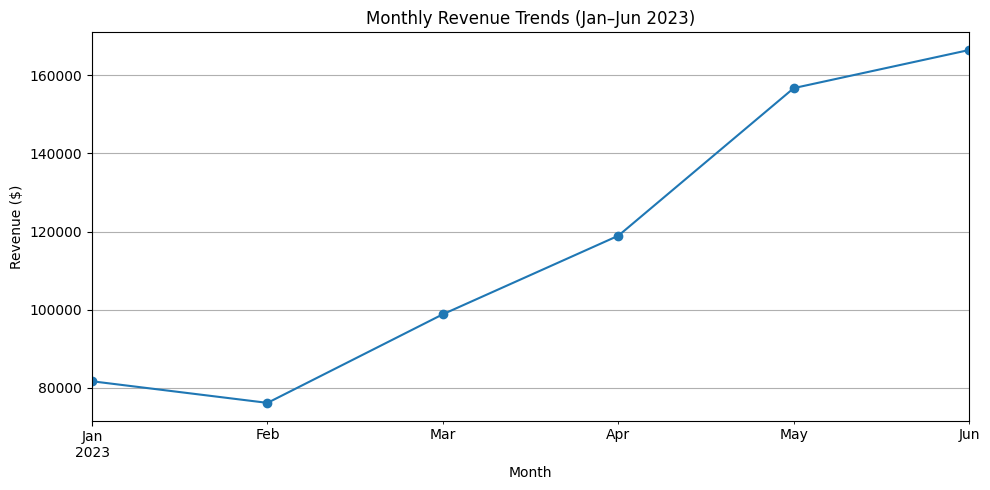

In [31]:
import matplotlib.pyplot as plt

# Create a line chart of monthly revenue
monthly_sales.plot(kind="line", marker="o", figsize=(10, 5))

# Add chart title and labels
plt.title("Monthly Revenue Trends (Jan–Jun 2023)")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")

# Display the chart
plt.grid(True)
plt.tight_layout()
plt.show()

#### Key Findings and Interpretation

The line chart shows an overall upward trend in monthly revenue from February through June, with a small decline in February compared with January. Revenue increased more noticeably between April and May, and June recorded the highest revenue of the six-month period.

Revenue more than doubled from February to June, increasing by approximately 118.7%. This upward trend suggests that sales performance strengthened during the first half of 2023.

## 8. Analyze Sales by Time of Day
**Business Question:** During which hours does the coffee shop generate the most revenue?


### 8.1 Calculate Revenue by Hour

In [32]:
# Extract the hour from each transaction time
df["transaction_hour"] = pd.to_datetime(
    df["transaction_time"].astype(str),
    format="%H:%M:%S"
).dt.hour

# Calculate total revenue by hour
hourly_sales = df.groupby("transaction_hour")["revenue"].sum()

# Sort hours chronologically
hourly_sales = hourly_sales.sort_index()

# Display hourly revenue
print(hourly_sales)

transaction_hour
6     21900.27
7     63526.47
8     82699.87
9     85169.53
10    88673.39
11    46319.14
12    40192.79
13    40367.45
14    41304.74
15    41733.10
16    41122.75
17    40134.31
18    34286.20
19    28446.68
20     2935.64
Name: revenue, dtype: float64


### 8.2 Visualize Hourly Revenue

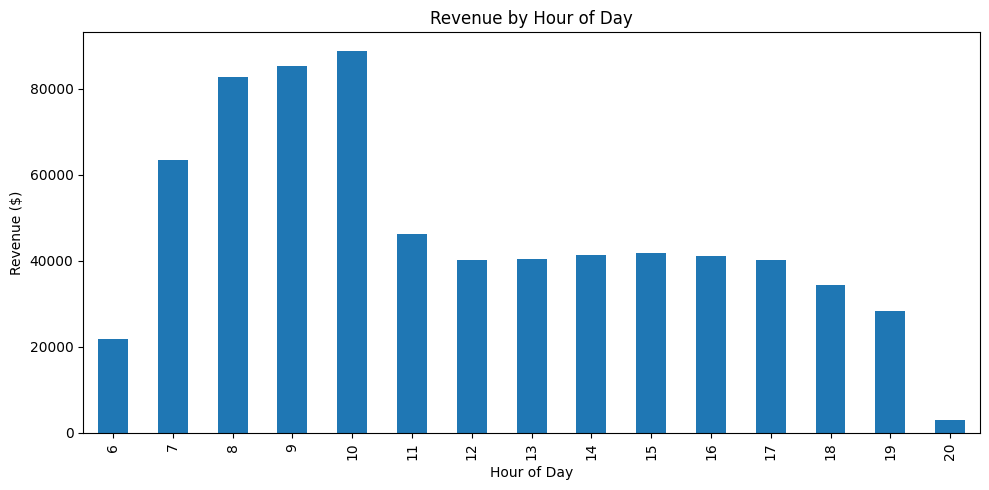

In [33]:
# Create a bar chart of hourly revenue
hourly_sales.plot(kind="bar", figsize=(10, 5))

# Add chart title and labels 
plt.title("Revenue by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue ($)")

# Display the chart
plt.tight_layout()
plt.show()

#### Key Findings and Interpretation

The coffee shop generated the highest hourly revenue at 10 AM (`$88,673.39`), followed by 9 AM (\$85,169.53) and 8 AM (\$82,699.87). Revenue was strongest between 8 AM and 10 AM, indicating that the morning is an important sales period.

Revenue declined noticeably after 10 AM, then remained relatively stable throughout the afternoon before decreasing further in the evening. The lowest revenue occurred at 8 PM (\$2,935.64).

These findings suggest that the business could prioritize staffing and inventory during peak morning hours to meet customer demand efficiently.

## 9. Analyze Sales by Product Type
**Business Question:** Which product types generate the most revenue?

### 9.1 Calculate Revenue by Product Type

In [13]:
# Calculate total revenue by product type
product_sales = df.groupby("product_type")["revenue"].sum()

# Sort products from highest to lowest revenue
product_sales = product_sales.sort_values(ascending=False)

# Display the top 10 products
print(product_sales.head(10))

product_type
Barista Espresso         91406.20
Brewed Chai tea          77081.95
Hot chocolate            72416.00
Gourmet brewed coffee    70034.60
Brewed Black tea         47932.00
Brewed herbal tea        47539.50
Premium brewed coffee    38781.15
Organic brewed coffee    37746.50
Scone                    36866.12
Drip coffee              31984.00
Name: revenue, dtype: float64


### 9.2 Visualize Top 10 Product Types

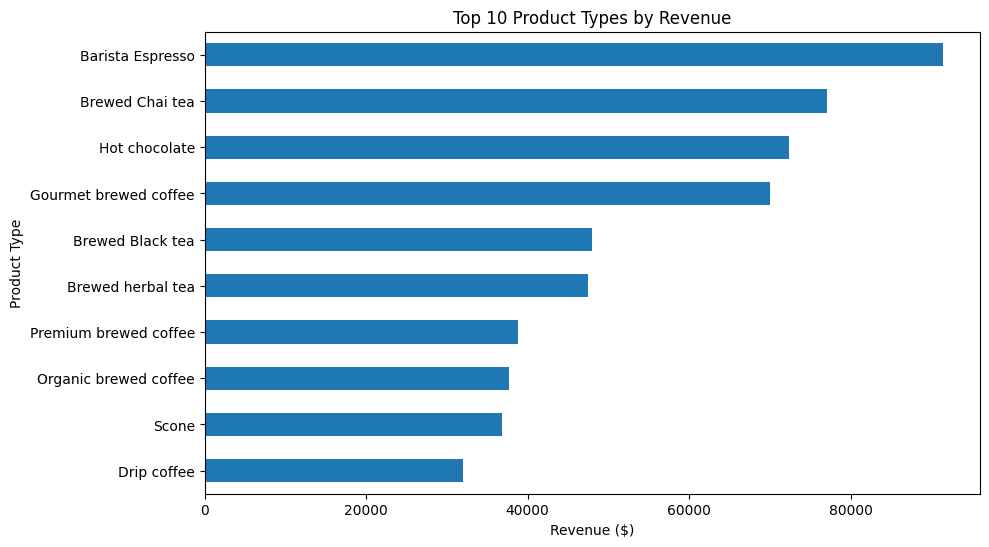

In [34]:
# Create a horizontal bar chart of the top 10 product types
product_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

# Add chart title and labels
plt.title("Top 10 Product Types by Revenue")
plt.xlabel("Revenue ($)")
plt.ylabel("Product Type")

# Display the chart
plt.tight_layout
plt.show()

#### Key Findings and Interpretation

Barista Espresso generated the highest revenue at \$91,406.20, followed by Brewed Chai Tea at \$77,081.95 and Hot Chocolate at \$72,416.00. Drip Coffee ranked lowest among the top 10 products at \$31,984.00.

The chart highlights the revenue differences between product types, showing that a few popular products contribute significantly to sales. The business could use these insights to prioritize inventory and maintain the availability of its highest-revenue products.

## 10. Analyze Average Transaction Value by Store
**Business Question:** How much does a customer spend per transaction in average at each store location?

### 10.1 Calculate the Average Transaction Value

In [35]:
# Calculate total revenue for each transaction
transaction_sales = df.groupby(
    ["store_location", "transaction_id"]
)["revenue"].sum()

# Calculate average transaction value for each store
avg_transaction = transaction_sales.groupby(
    level="store_location"
).mean()

# Sort stores from highest to lowest
avg_transaction = avg_transaction.sort_values(ascending=False)

# Display the results
print(avg_transaction.round(2))

store_location
Lower Manhattan    4.81
Hell's Kitchen     4.66
Astoria            4.59
Name: revenue, dtype: float64


### 10.2 Visualize Average Transaction Value

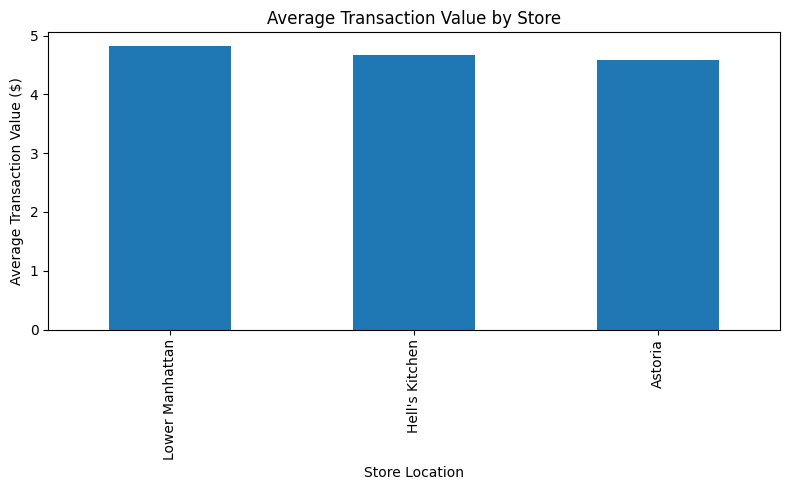

In [36]:
# Create a bar chart of average transaction value
avg_transaction.plot(kind="bar", figsize=(8, 5))

# Add chart title and labels
plt.title("Average Transaction Value by Store")
plt.xlabel("Store Location")
plt.ylabel("Average Transaction Value ($)")

# Display the chart
plt.tight_layout()
plt.show()

#### Key Findings

Lower Manhattan had the highest average transaction value at \$4.81, followed by Hell's Kitchen at $4.66 and Astoria at \$4.59. Although the differences are relatively small, Lower Manhattan customers spent slightly more per transaction on average.

These findings suggest that the business could explore opportunities to increase average spending at Hell's Kitchen and Astoria through product recommendations, combo deals, or upselling strategies.

## 11. Analyze Sales by Day of the Week
**Business Question:** Which days of the week generate the most revenue?

### 11.1 Calculate Revenue by Day of the Week 

In [37]:
# Calculate total revenue for each date
daily_revenue = df.groupby("transaction_date")["revenue"].sum()

# Extract the day of the week
daily_revenue.index = daily_revenue.index.day_name()

# Calculate average revenue for each day of the week
avg_daily_sales = daily_revenue.groupby(level=0).mean()

# Define the chronological order of the days
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Arrange days in chronological order
avg_daily_sales = avg_daily_sales.reindex(day_order)

# Rename the index for clearer output
avg_daily_sales.index.name = "day_of_week"

# Display average daily revenue
print(avg_daily_sales.round(2))

day_of_week
Monday       3910.66
Tuesday      3825.23
Wednesday    3858.21
Thursday     3875.68
Friday       3898.96
Saturday     3875.78
Sunday       3781.94
Name: revenue, dtype: float64


### 11.2 Visualize Average Daily Revenue

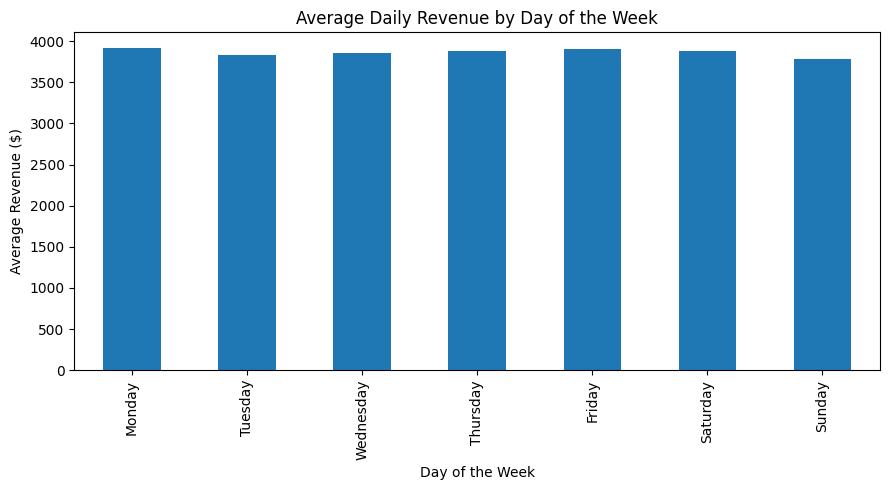

In [38]:
# Create a bar chart of average daily revenue
avg_daily_sales.plot(kind="bar", figsize=(9, 5))

# Add chart title and labels
plt.title("Average Daily Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Revenue ($)")

# Display the chart
plt.tight_layout()
plt.show()

#### Key Findings and Interpretation

Monday had the highest average daily revenue at \$3,910.66, while Sunday had the lowest at \$3,781.94. Overall, average daily revenue remained relatively consistent throughout the week, with only small differences between days.

These findings suggest that sales are fairly stable across the week. The business could maintain consistent staffing and inventory levels while making small adjustments based on daily demand.

## 12. Overall Business Insights and Recommendations

### 12.1 Key Business Insights

**1. Product Category Performance**

Coffee and Tea were the top revenue-generating categories, contributing approximately 66.7% of total revenue.

**2. Store Performance**

Hell's Kitchen generated the highest total revenue at \$236,511.17, while Lower Manhattan had the highest average transaction value at \$4.81.

**3. Monthly Revenue Trends**

Monthly revenue increased significantly from February through June, reaching its highest point in June at $166,485.88.

**4. Peak Sales Hours**

Revenue peaked between 8 AM and 10 AM, with 10 AM generating the highest hourly revenue at $88,673.39.

**5. Product Type Performance**

Barista Espresso was the highest revenue-generating product type at $91,406.20.

**6. Weekly Sales Patterns**

Average daily revenue remained relatively consistent throughout the week, with Monday recording the highest average at $3,910.66.



### 12.2 Business Recommendations


#### Recommendations

1. **Focus on popular products:** Maintain sufficient inventory of high-revenue categories such as Coffee and Tea, especially popular products like Barista Espresso.

2. **Optimize staffing:** Allocate sufficient employees during peak morning hours, particularly between 8 AM and 10 AM.

3. **Improve average transaction value:** Explore combo deals, product recommendations, and upselling opportunities at Hell's Kitchen and Astoria.

4. **Monitor store performance:** Continue tracking revenue and average transaction value across all three locations to identify opportunities for improvement.

5. **Track monthly sales trends:** Monitor monthly revenue to understand growth patterns and support future inventory and staffing decisions.

## 13. Conclusion

This project analyzed coffee shop sales data from January to June 2023 to evaluate sales performance across product categories, store locations, product types, and time periods.

The analysis found that Coffee and Tea were the main revenue-generating categories, Barista Espresso was the top-performing product type, and morning hours (particularly 8 AM–10 AM) generated the highest hourly revenue. Monthly revenue also showed an overall upward trend, reaching its highest level in June.

Overall, these findings provide useful insights into customer purchasing patterns and sales performance. The results can help the business make more informed decisions about inventory management, staffing, and sales strategies.